# Bulk ATAC-seq part 3: differential accessibility with DiffBind and DESeq2

**Case study: How do FOXA1 and HNF4A change the chromatin of a blood cell line?**

Hansen JL, Loell KJ, Cohen BA. *A test of the pioneer factor hypothesis using ectopic liver gene activation.* eLife (2022) 11:e73358. https://doi.org/10.7554/eLife.73358

**Research questions:**

1. How good are the ATAC-seq libraries?
2. Which regions open (or close) when FOXA1 and HNF4A are expressed?
3. Do the opened regions contain FOXA1 and HNF4A motifs, and do they lie near the genes that are switched on?

This notebook answers questions 2 and 3, compares our results with the paper, and ends with a conclusion on all three questions.

## Introduction

In [part 2](part_2_consensus_peaks_macs_diff.ipynb) we built a consensus peak set, counted fragments per sample, and saw that MACS3 `bdgdiff` cannot separate real differences from the variation between replicates. Here we use statistical methods that **model the variation between replicates**.

Both methods treat the fragment counts like RNA-seq read counts: for each region, the counts of the four samples are modelled with a **negative binomial** distribution, whose variance (the *dispersion*) is estimated from the replicates and shared across regions with a similar mean. A region is called differentially accessible if the difference between conditions is large compared with this variance, with a false discovery rate (FDR) across all regions tested.

- [**DESeq2**](https://bioconductor.org/packages/DESeq2) (Love et al., 2014) is a general method for count data (RNA-seq, ATAC-seq, ChIP-seq, ...). You provide a count matrix and a design.
- [**DiffBind**](https://bioconductor.org/packages/DiffBind) (Ross-Innes et al., 2012; Stark & Brown) wraps the whole peak-based workflow: it reads peak files and BAM files, builds a consensus, counts, normalises, and runs DESeq2 or edgeR for you.

Plan of this notebook:

1. **DiffBind**: from peak and BAM files to differentially accessible regions (DARs), and the effect of normalisation;
2. **DESeq2** on our own count matrix from part 2;
3. comparing DiffBind, DESeq2 and MACS3 `bdgdiff`;
4. annotating DARs to genes with ChIPseeker;
5. linking the opened regions to the genes activated in the [bulk RNA-seq practical](../bulk-rna-seq/index.md);
6. motif enrichment with HOMER: which transcription factors open (and close) the regions?
7. saving the results, and a comparison with the paper.

This notebook uses the **R** kernel. As before, all data are restricted to chr17.

## Step 0: Setup

This notebook uses R, with DiffBind, DESeq2, apeglm, ChIPseeker, the hg38 annotation packages and UpSetR, and the command-line motif tool HOMER. They can all be installed in one mamba environment. Create it once and register it as a Jupyter kernel, in a terminal (not in this notebook):

```
mamba create -n atac-r -c conda-forge -c bioconda r-base=4.4 r-irkernel bioconductor-diffbind bioconductor-deseq2 bioconductor-apeglm bioconductor-chipseeker bioconductor-txdb.hsapiens.ucsc.hg38.knowngene bioconductor-org.hs.eg.db r-upsetr r-ggplot2 r-pheatmap homer
mamba activate atac-r
R -e 'IRkernel::installspec(name = "atac-r", displayname = "R (atac-r)")'
jupyter kernelspec list   # the kernel atac-r should be listed
```

Then (re)start Jupyter and select the kernel "R (atac-r)". The course data are in the shared folder on the teaching server, or in the folder `course_data` next to this notebook (see Step 0 of part 1); we work in `data/part_3`, next to this notebook.

In [1]:
suppressPackageStartupMessages({
    library(DiffBind)
    library(DESeq2)
    library(apeglm)
    library(GenomicRanges)
    library(ChIPseeker)
    library(TxDb.Hsapiens.UCSC.hg38.knownGene)
    library(org.Hs.eg.db)
    library(ggplot2)
    library(pheatmap)
    library(UpSetR)
})
options(repr.plot.width = 7, repr.plot.height = 5)

# The folder of this notebook (the kernel starts there). Kept when you run this cell again after setwd below.
if (!exists("here")) here <- getwd()

# Course data (read-only): the shared folder on the teaching server, otherwise the folder course_data next to this notebook
bulk <- "/data/teachers/data/bulk_atac_seq/hansen_foxa1_hnf4a"
if (!dir.exists(bulk)) bulk <- file.path(here, "course_data")

# Your own working folder, in the folder data next to this notebook
out <- file.path(here, "data", "part_3")
dir.create(out, recursive = TRUE, showWarnings = FALSE)
setwd(out)

# Results of part 2 (yours if you ran it, otherwise the pre-generated ones)
nb02 <- file.path(here, "data", "part_2")
if (!file.exists(file.path(nb02, "counts_matrix.tsv"))) nb02 <- file.path(bulk, "nb02_generated")
cat("part 2 results:", sub(paste0(here, "/"), "", nb02, fixed = TRUE), "\n")

part 2 results: data/part_2 


We describe the design in a table with one row per sample, as in the [bulk RNA-seq practical](../bulk-rna-seq/part_2_differential_expression.ipynb): the condition and the replicate can be read from the sample names (`U` = uninduced, `I` = induced, followed by the replicate number). We turn the condition into an R factor and choose its **reference level** (uninduced): fold changes are always expressed relative to the reference, so a positive fold change means "more accessible after induction".

In [2]:
sample_names <- c("FOXA1HNF4A_U1", "FOXA1HNF4A_U2", "FOXA1HNF4A_I1", "FOXA1HNF4A_I2")
samples <- data.frame(
    row.names = sample_names,
    sample    = sample_names,
    dox       = ifelse(grepl("_U", sample_names), "uninduced", "induced"),  # U = uninduced, I = induced
    replicate = as.integer(sub(".*_[UI]", "", sample_names))                # the number after U or I
)
# the first level of the factor is the reference
samples$dox <- factor(samples$dox, levels = c("uninduced", "induced"))
samples

,sample,dox,replicate
,<chr>,<fct>,<int>
FOXA1HNF4A_U1,FOXA1HNF4A_U1,uninduced,1
FOXA1HNF4A_U2,FOXA1HNF4A_U2,uninduced,2
FOXA1HNF4A_I1,FOXA1HNF4A_I1,induced,1
FOXA1HNF4A_I2,FOXA1HNF4A_I2,induced,2


## Step 1: DiffBind

### 1a. The DiffBind sample sheet

DiffBind starts from a table with one row per sample: metadata columns (`SampleID`, `Tissue`, `Factor`, `Condition`, `Treatment`, `Replicate`), the BAM file with the reads (`bamReads`), and the peak file (`Peaks`, with `PeakCaller` telling DiffBind the format). We use the chr17 BAM files and the per-sample MACS3 peaks from part 2.

In [3]:
sample_sheet <- data.frame(
    SampleID   = samples$sample,
    Tissue     = "K562",
    Factor     = "FOXA1-HNF4A",
    Condition  = samples$dox,
    Replicate  = samples$replicate,
    bamReads   = file.path(bulk, "data_generated", samples$sample, paste0(samples$sample, ".filtered.chr17.bam")),
    Peaks      = file.path(nb02, "peaks", paste0(samples$sample, "_peaks.narrowPeak")),
    PeakCaller = "narrow"
)
# stop with an error if a file is missing; dba() reads the peak files and merges them
stopifnot(all(file.exists(sample_sheet$bamReads)), all(file.exists(sample_sheet$Peaks)))
atac <- dba(sampleSheet = sample_sheet)
atac

FOXA1HNF4A_U1 K562 FOXA1-HNF4A uninduced  1 narrow

FOXA1HNF4A_U2 K562 FOXA1-HNF4A uninduced  2 narrow

FOXA1HNF4A_I1 K562 FOXA1-HNF4A induced  1 narrow

FOXA1HNF4A_I2 K562 FOXA1-HNF4A induced  2 narrow



4 Samples, 5224 sites in matrix (6469 total):
             ID Tissue      Factor Condition Replicate Intervals
1 FOXA1HNF4A_U1   K562 FOXA1-HNF4A uninduced         1      3520
2 FOXA1HNF4A_U2   K562 FOXA1-HNF4A uninduced         2      3706
3 FOXA1HNF4A_I1   K562 FOXA1-HNF4A   induced         1      5198
4 FOXA1HNF4A_I2   K562 FOXA1-HNF4A   induced         2      4923

The `Intervals` column is the number of peaks per sample. DiffBind has already merged all peaks into a consensus. A first look at the data: the correlation between samples based on **which peaks they share** (occupancy), before counting any reads:

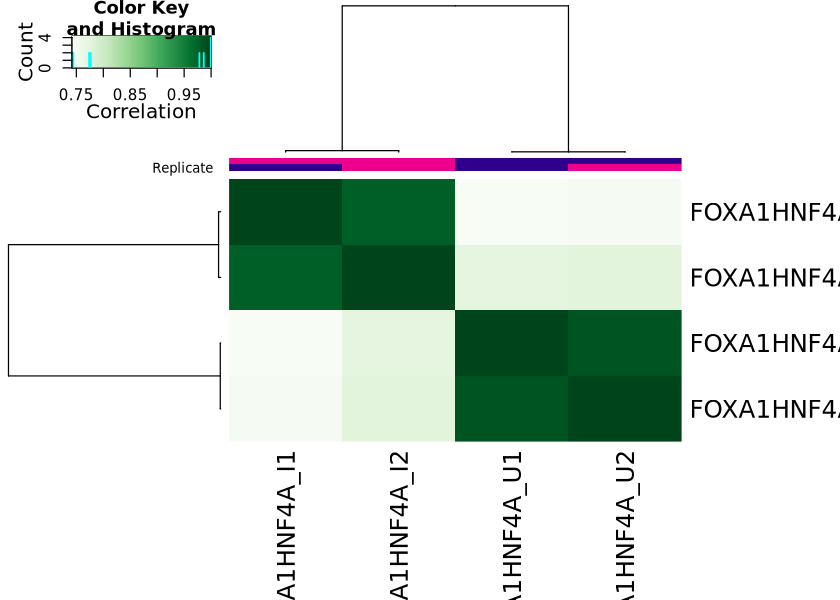

In [4]:
plot(atac)

### 1b. Counting

`dba.count` builds the consensus peak set and counts the fragments of every sample in it. The options follow what we did by hand in part 2:

- `minOverlap = 2`: keep regions that are peaks in at least 2 samples (the default);
- `summits = 250`: re-centre each consensus region on its summit and make it 2 × 250 + 1 = 501 bp wide, like our fixed-width peaks;
- the reads are paired, so we tell DiffBind to count fragments (`singleEnd = FALSE`).

Counting reads all BAM files and takes a minute or two.

In [4]:
atac$config$singleEnd <- FALSE
atac$config$cores <- 4
# bUseSummarizeOverlaps: count with Bioconductor's summarizeOverlaps, which handles read pairs as fragments
atac <- dba.count(atac, minOverlap = 2, summits = 250, bUseSummarizeOverlaps = TRUE)
atac

Computing summits...

Re-centering peaks...

Reads will be counted as Paired-end.



4 Samples, 5223 sites in matrix:
             ID Tissue      Factor Condition Replicate   Reads FRiP
1 FOXA1HNF4A_U1   K562 FOXA1-HNF4A uninduced         1 1550645 0.40
2 FOXA1HNF4A_U2   K562 FOXA1-HNF4A uninduced         2 1617872 0.44
3 FOXA1HNF4A_I1   K562 FOXA1-HNF4A   induced         1 1814126 0.50
4 FOXA1HNF4A_I2   K562 FOXA1-HNF4A   induced         2 1633828 0.50

The table now has `Reads` (fragments in the BAM file) and `FRiP` (the fraction of them inside the consensus peaks) for every sample. With counts, the correlation heatmap and the PCA are based on **accessibility**, not just on peak presence. Do samples cluster by condition?

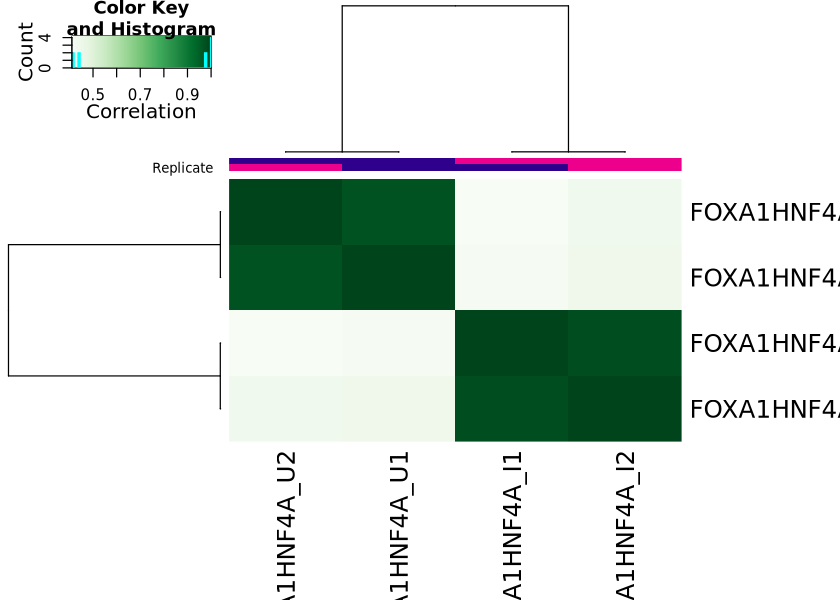

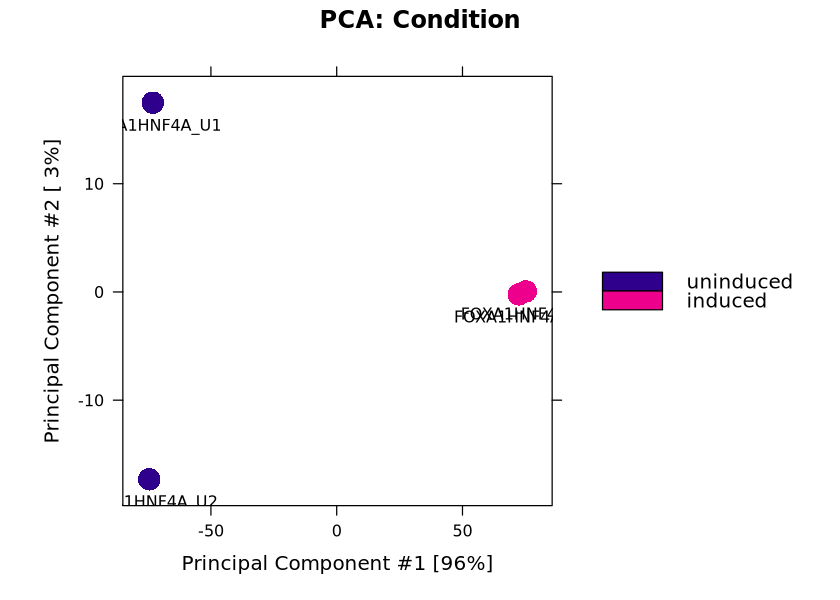

In [6]:
plot(atac)
dba.plotPCA(atac, attributes = DBA_CONDITION, label = DBA_ID)

### 1c. Normalisation

Samples have different sequencing depths, so raw counts are not comparable. Normalisation computes a **size factor** per sample. Which reads you use to compute it matters:

| method | idea | assumes |
|---|---|---|
| library size, full (`DBA_LIBSIZE_FULL`, DiffBind's default) | total fragments in the BAM | same fraction of background in every sample |
| library size, reads in peaks (`DBA_LIBSIZE_PEAKREADS`) | total fragments in consensus peaks | same total accessibility in every sample |
| RLE (`DBA_NORM_RLE`, DESeq2's method) | median ratio to a pseudo-reference over all peaks | most peaks don't change |
| background bins (`background = TRUE`) | counts in large (15 kb) bins across the genome | background is the same in every sample |

If FRiP differs between samples (part 2), the first two give different answers. Let's compare the size factors:

In [7]:
size_factors_of <- function(dba_obj, ...) {  # normalise, then read back the size factors
    dba.normalize(dba.normalize(dba_obj, ...), bRetrieve = TRUE)$norm.factors
}
# one size factor per sample for each method; a sample with a higher factor gets its counts divided by more
size_factors <- data.frame(
    sample = samples$sample,
    FRiP = dba.show(atac)$FRiP,
    libsize_full = round(size_factors_of(atac, normalize = DBA_NORM_LIB, library = DBA_LIBSIZE_FULL), 2),
    RLE_in_peaks = round(size_factors_of(atac, normalize = DBA_NORM_RLE, library = DBA_LIBSIZE_PEAKREADS), 2)
)
size_factors

,sample,FRiP,libsize_full,RLE_in_peaks
,<chr>,<dbl>,<dbl>,<dbl>
FOXA1HNF4A_U1,FOXA1HNF4A_U1,0.40,0.94,0.83
FOXA1HNF4A_U2,FOXA1HNF4A_U2,0.44,0.98,0.97
FOXA1HNF4A_I1,FOXA1HNF4A_I1,0.50,1.10,1.18
FOXA1HNF4A_I2,FOXA1HNF4A_I2,0.50,0.99,1.07


We start with DiffBind's default (library size), and compare with RLE below.

### 1d. Contrast and analysis

We compare **induced** with **uninduced**. DiffBind only sets up contrasts between groups of at least 3 samples by default; we have 2 replicates per condition, so we lower this with `minMembers = 2`. Two replicates is the minimum for any statistics: the dispersion is estimated from very little information per region, and DESeq2 relies heavily on sharing it across regions. By default `dba.analyze` runs only DESeq2; with `method = DBA_ALL_METHODS` it runs both DESeq2 and edgeR.

In [5]:
atac <- dba.normalize(atac)  # default: library size
# contrast = c(column of the sample sheet, numerator group, denominator group); minMembers: smallest group allowed
atac <- dba.contrast(atac, contrast = c("Condition", "induced", "uninduced"), minMembers = 2)
atac <- dba.analyze(atac, method = DBA_ALL_METHODS)
dba.show(atac, bContrasts = TRUE)

Computing results names...

Applying Blacklist/Greylists...

Genome detected: Hsapiens.UCSC.hg38

Applying blacklist...

Removed: 0 of 5223 intervals.

No intervals removed.

Normalize edgeR with defaults...

Analyzing...



,Factor,Group,Samples,Group2,Samples2,DB.edgeR,DB.DESeq2
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Condition,induced,2,uninduced,2,3468,3085


The `DB.DESeq2` and `DB.edgeR` columns give the number of differentially accessible sites at FDR < 0.05. How much do the two methods agree?

Generating report-based DBA object...



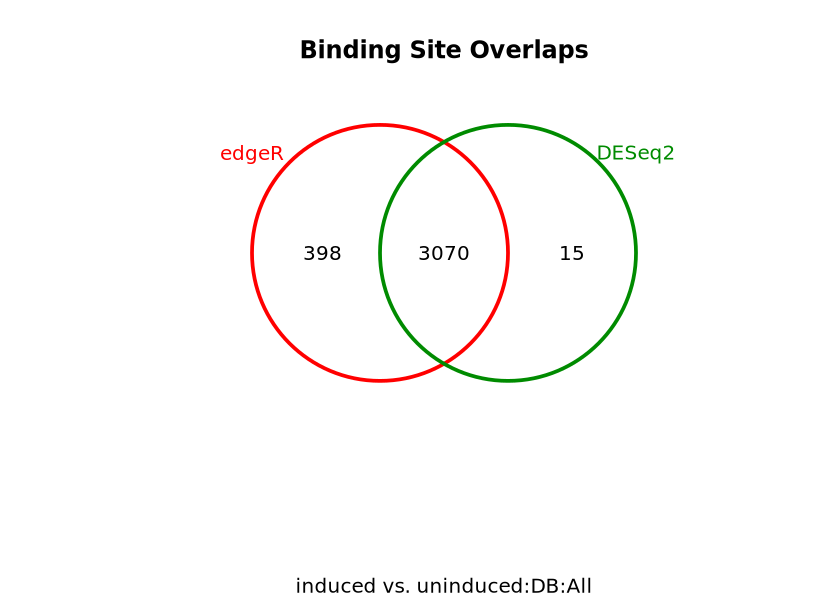

In [9]:
dba.plotVenn(atac, contrast = 1, method = DBA_ALL_METHODS)

`dba.report` returns the significant sites as a `GRanges` object, with the mean normalised accessibility (`Conc`, log2) per condition, the log2 fold change (`Fold`, positive = more accessible after induction), the p-value and the FDR:

In [10]:
# th: FDR threshold of the report
db_diffbind <- dba.report(atac, method = DBA_DESEQ2, th = 0.05)
cat(sum(db_diffbind$Fold > 0), "sites more accessible after induction,", sum(db_diffbind$Fold < 0), "less accessible\n")
head(db_diffbind)

2110 sites more accessible after induction, 975 less accessible


GRanges object with 6 ranges and 6 metadata columns:
       seqnames            ranges strand |      Conc Conc_induced
          <Rle>         <IRanges>  <Rle> | <numeric>    <numeric>
  1536    chr17 31803706-31804206      * |   9.17070     10.11685
  1242    chr17 28698361-28698861      * |   9.38208     10.28687
  3583    chr17 59469755-59470255      * |   8.83419      9.78299
  3450    chr17 57937990-57938490      * |   8.85864      9.83081
  2931    chr17 48871605-48872105      * |   9.11047      9.95605
  1208    chr17 28398165-28398665      * |   8.78441      9.66496
       Conc_uninduced      Fold      p-value          FDR
            <numeric> <numeric>    <numeric>    <numeric>
  1536        5.40011   4.68480 5.02193e-120 2.62296e-116
  1242        6.41332   3.85727 1.55175e-118 4.05241e-115
  3583        4.99214   4.75182  1.16732e-99  2.03231e-96
  3450        4.14857   5.61617  1.93230e-91  2.52310e-88
  2931        6.81010   3.13209  1.59721e-88  1.66845e-85
  1208       

DiffBind has plotting functions for the result. An **MA plot** shows the fold change against the mean accessibility of each site (significant ones in red); a **volcano plot** shows the fold change against significance; the **box plot** shows the accessibility of the significant sites per group.

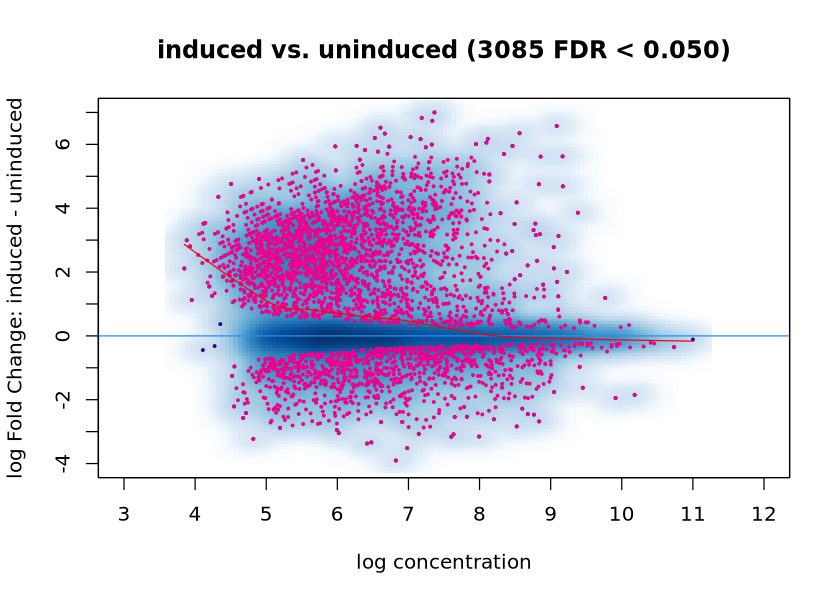

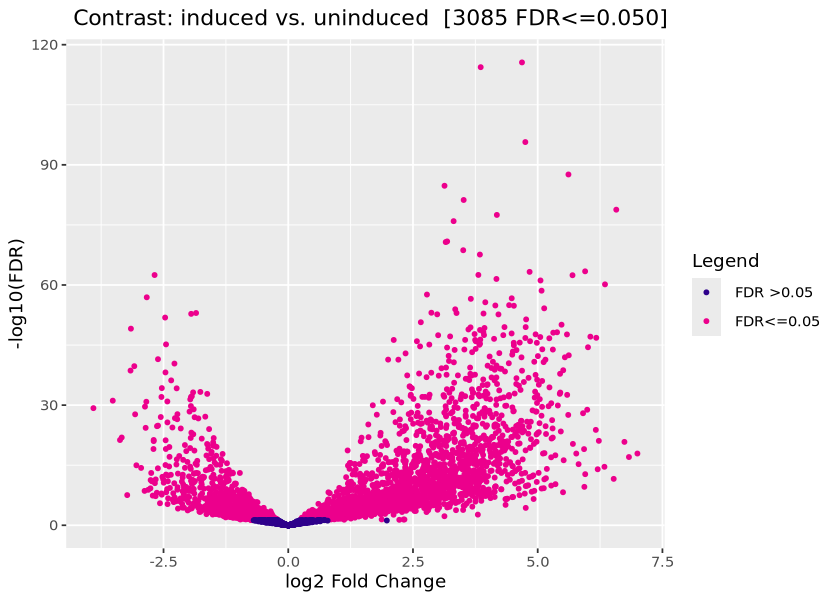

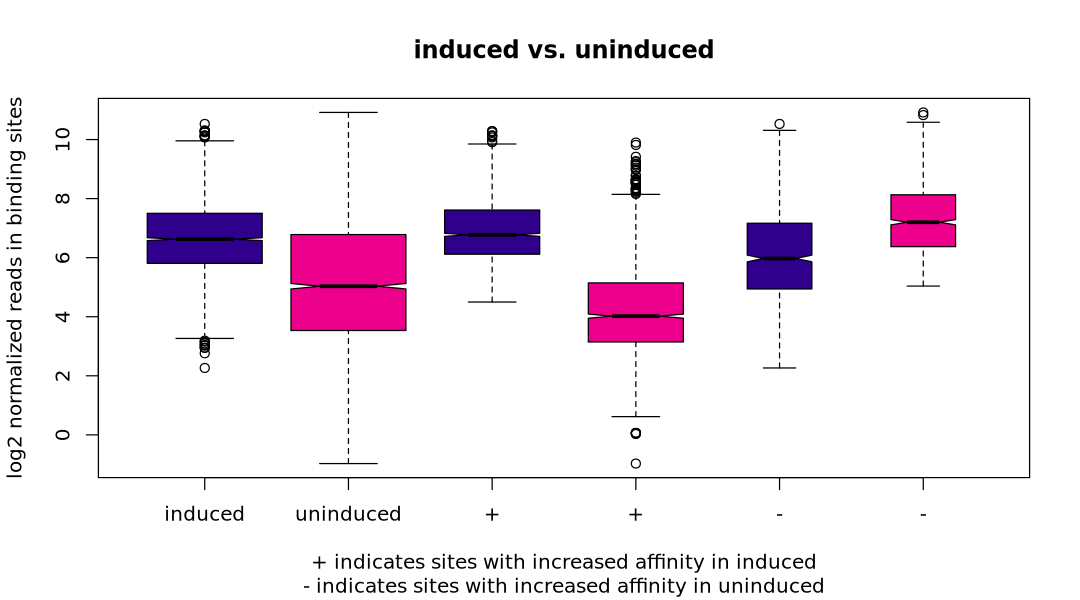

In [7]:
dba.plotMA(atac, method = DBA_DESEQ2)
dba.plotVolcano(atac, method = DBA_DESEQ2)
# a wider figure, otherwise R drops the "uninduced" label under the second box
options(repr.plot.width = 9)
dba.plotBox(atac, method = DBA_DESEQ2)
options(repr.plot.width = 7)

About 3,100 of the ~5,200 consensus sites on chr17 change significantly, two thirds of them opening after induction. The MA plot shows the same: a dense band of sites with large positive fold changes, mostly at low to medium accessibility (sites that were closed or weak before induction), and fewer with negative fold changes. The cloud of the strongest, most accessible sites (right side of the plot) is centred on 0.

Does the choice of normalisation change this? Let's repeat the analysis with RLE normalisation on the reads in peaks (`normalize = DBA_NORM_RLE, library = DBA_LIBSIZE_PEAKREADS`) and compare the number of sites in each direction:

In [12]:
# same analysis, only the normalisation changes: RLE (DESeq2's method) computed on the reads in peaks
atac_rle <- dba.normalize(atac, normalize = DBA_NORM_RLE, library = DBA_LIBSIZE_PEAKREADS)
atac_rle <- dba.analyze(atac_rle, method = DBA_DESEQ2)
db_rle <- dba.report(atac_rle, method = DBA_DESEQ2, th = 0.05)
data.frame(normalisation = c("library size (full)", "RLE (reads in peaks)"),
           opened = c(sum(db_diffbind$Fold > 0), sum(db_rle$Fold > 0)),
           closed = c(sum(db_diffbind$Fold < 0), sum(db_rle$Fold < 0)))

Analyzing...

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



normalisation,opened,closed
<chr>,<int>,<int>
library size (full),2110,975
RLE (reads in peaks),1961,1513


Library-size normalisation assumes the same fraction of background reads in every sample. RLE on reads in peaks assumes instead that **most peaks don't change**, and centres the fold changes of the typical peak around zero. Neither is always right: check the MA plot (is the cloud of unchanged sites centred on 0?) and think about the biology (could the treatment really open or close chromatin globally?).

Here the biology is clear: FOXA1 and HNF4A are pioneer factors that open hundreds of new regions, and more than half of the chr17 sites change, mostly upwards. That breaks the assumption of RLE. With RLE the induced samples get larger size factors (1.07-1.18 versus 0.83-0.97, see the table above): their counts are divided by more, so the many opened sites pull every other site down, and about 540 extra sites become "closed". With library-size normalisation the strongest, most accessible sites stay centred on 0 in the MA plot. This is the same effect we saw for *ACTG1* in part 1 and for `bdgdiff` in part 2.

So here we keep **library-size normalisation** (DiffBind's default), and we use it below for DESeq2 too. In an experiment where only a few regions change, RLE is usually the better choice; the point is to check, not to follow a default.

## Step 2: DESeq2 on the count matrix

DiffBind is convenient, but it hides the steps. Now we use DESeq2 directly on the count matrix we built in [part 2](part_2_consensus_peaks_macs_diff.ipynb) (fixed-width consensus peaks, counted with featureCounts). This is the same workflow as for RNA-seq, with peaks instead of genes. Step 3 of the [bulk RNA-seq practical, part 2](../bulk-rna-seq/part_2_differential_expression.ipynb) explains how DESeq2 models the counts (negative binomial distribution, size factors, dispersion, shrinkage); here we focus on what is different for ATAC-seq.

In [13]:
counts <- as.matrix(read.delim(file.path(nb02, "counts_matrix.tsv"), row.names = 1, check.names = FALSE))
# same sample order as the sample sheet: DESeq2 matches columns of the counts to rows of colData by position
counts <- counts[, samples$sample]
dim(counts)
head(counts)
colSums(counts)

[1] 5516    4

,FOXA1HNF4A_U1,FOXA1HNF4A_U2,FOXA1HNF4A_I1,FOXA1HNF4A_I2
peak1,52,45,77,49
peak3,18,24,105,107
peak6,30,38,70,62
peak7,11,18,71,39
peak8,21,22,49,41
peak9,42,37,65,57


FOXA1HNF4A_U1 FOXA1HNF4A_U2 FOXA1HNF4A_I1 FOXA1HNF4A_I2 
       648115        758299        951890        861668

### 2a. Design and normalisation

The design has one factor, `~ dox`. DESeq2 would normally estimate size factors with RLE; following Step 1c, we replace them with **library-size** factors: the total number of fragments of each sample on chr17 (from part 2), divided by their geometric mean so they are centred on 1. `DESeq()` uses size factors that are already set instead of estimating its own.

In [14]:
dds <- DESeqDataSetFromMatrix(countData = counts, colData = samples, design = ~ dox)
# library-size factors: all filtered fragments per sample (as counted by DiffBind), centred on 1 (geometric mean)
library_size <- setNames(dba.show(atac)$Reads, dba.show(atac)$ID)[samples$sample]
sizeFactors(dds) <- library_size / exp(mean(log(library_size)))
# compare with the RLE factors DESeq2 would have used
data.frame(library_size = round(sizeFactors(dds), 2), RLE = round(sizeFactors(estimateSizeFactors(dds)), 2))
# DESeq() runs the remaining steps: dispersions, model fit and Wald tests
dds <- DESeq(dds)
resultsNames(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



,library_size,RLE
,<dbl>,<dbl>
FOXA1HNF4A_U1,0.94,0.84
FOXA1HNF4A_U2,0.98,0.98
FOXA1HNF4A_I1,1.10,1.17
FOXA1HNF4A_I2,0.99,1.07


[1] "Intercept"                "dox_induced_vs_uninduced"

Before testing, look at the samples. The **variance-stabilising transformation** (`vst`) puts counts on a log2-like scale where the variance no longer depends on the mean, which is what PCA and distance plots need.

using ntop=500 top features by variance

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the DESeq2 package.
  Please report the issue to the authors.”


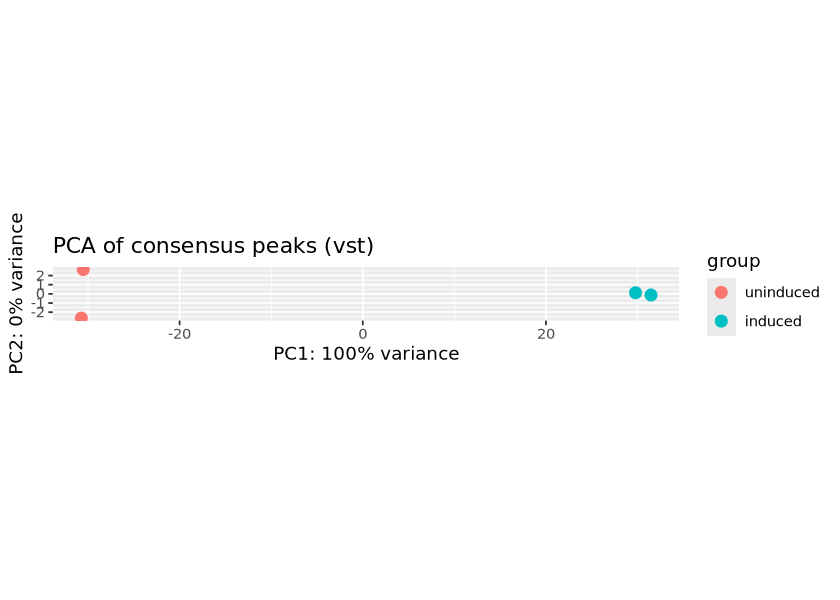

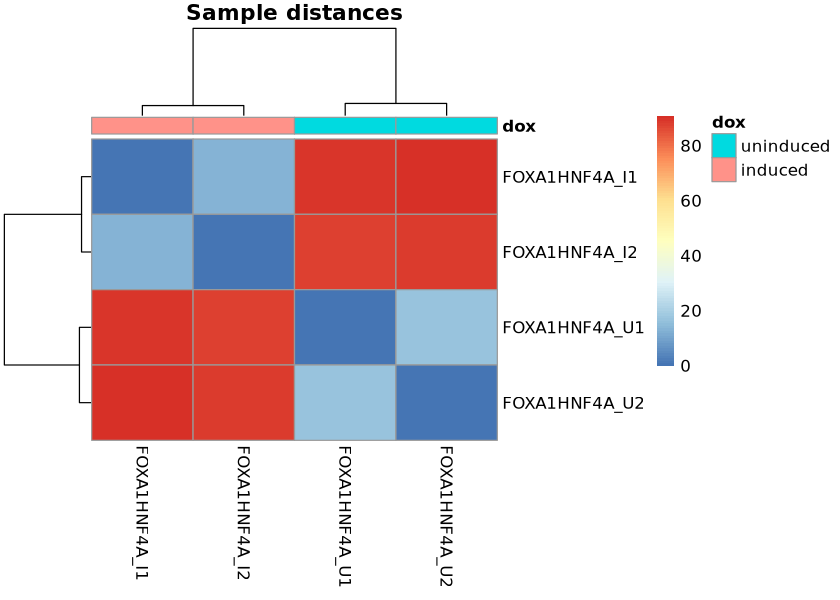

In [15]:
# vst() fits the transformation on a subset of 1000 regions; on one chromosome we use the full version
vsd <- varianceStabilizingTransformation(dds, blind = TRUE)
plotPCA(vsd, intgroup = "dox") + ggtitle("PCA of consensus peaks (vst)")

# Euclidean distances between samples (t(): samples as rows)
sample_dist <- as.matrix(dist(t(assay(vsd))))
pheatmap(sample_dist, annotation_col = samples[, "dox", drop = FALSE], main = "Sample distances")

The first principal component separates the conditions, and the replicates are close together.

Now the test for induced versus uninduced. `alpha = 0.05` is the FDR threshold used for the summary and for independent filtering (DESeq2 removes regions with very low counts, which can never be significant, to gain power).

In [16]:
# contrast = c(factor, numerator, denominator): log2 fold change induced / uninduced
res <- results(dds, contrast = c("dox", "induced", "uninduced"), alpha = 0.05)
summary(res)
head(res[order(res$padj), ])


out of 5516 with nonzero total read count
adjusted p-value < 0.05
LFC > 0 (up)       : 2111, 38%
LFC < 0 (down)     : 920, 17%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 15)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



log2 fold change (MLE): dox induced vs uninduced 
Wald test p-value: dox induced vs uninduced 
DataFrame with 6 rows and 6 columns
          baseMean log2FoldChange     lfcSE      stat       pvalue         padj
         <numeric>      <numeric> <numeric> <numeric>    <numeric>    <numeric>
peak1994   587.501        4.67433  0.209453   22.3168 2.53859e-110 1.40029e-106
peak1615   670.322        3.82853  0.179172   21.3680 2.65495e-101  7.32237e-98
peak4612   456.226        4.71995  0.233495   20.2143  7.32474e-91  1.34678e-87
peak4445   463.428        5.68153  0.289080   19.6538  5.36395e-86  7.39689e-83
peak2312   533.499        6.73886  0.362145   18.6082  2.75767e-77  3.04226e-74
peak3758   551.835        3.14594  0.170615   18.4388  6.41505e-76  5.89757e-73

Fold changes of regions with few fragments are noisy: a change from 2 to 8 fragments is a log2 fold change of 2 but means little. **Shrinkage** (here with `apeglm`) pulls such uncertain fold changes towards zero, while keeping strong, well-supported ones. Use shrunken fold changes for ranking and plotting; the p-values do not change.

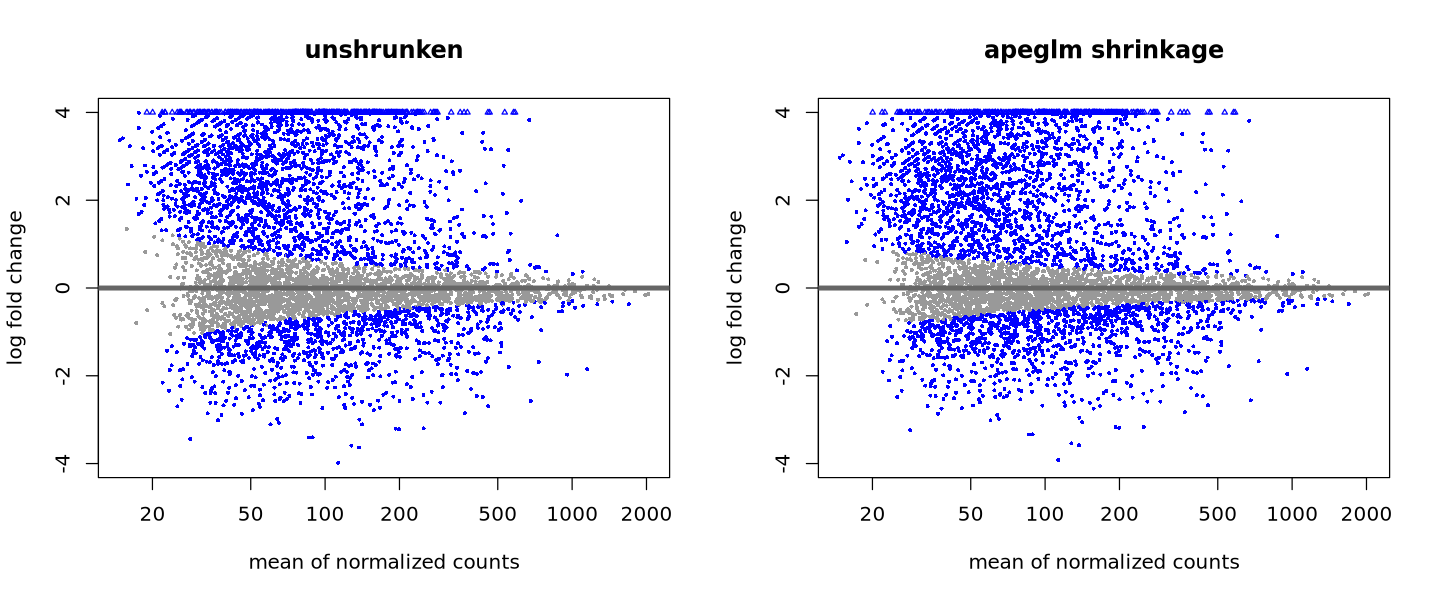

In [17]:
# apeglm shrinks one coefficient, named as in resultsNames(dds)
res_shrunk <- lfcShrink(dds, coef = "dox_induced_vs_uninduced", type = "apeglm", quiet = TRUE)
# two plots side by side (wider figure, 1 row x 2 columns)
options(repr.plot.width = 12, repr.plot.height = 5)
par(mfrow = c(1, 2))
plotMA(res, ylim = c(-4, 4), main = "unshrunken")
plotMA(res_shrunk, ylim = c(-4, 4), main = "apeglm shrinkage")
par(mfrow = c(1, 1))
options(repr.plot.width = 7, repr.plot.height = 5)

A volcano plot with the shrunken fold changes, and the normalised counts of the most significant region in each sample. Always look at the counts of your top hits: do both replicates agree?

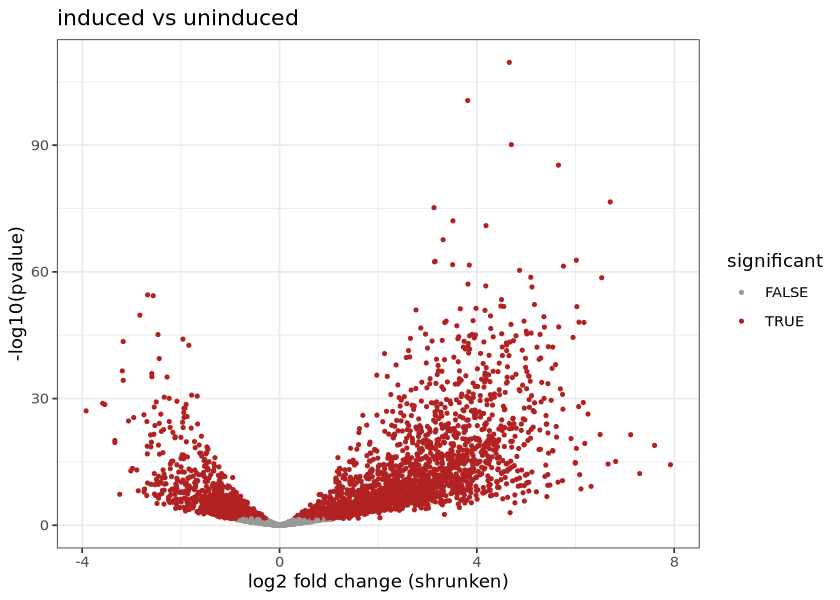

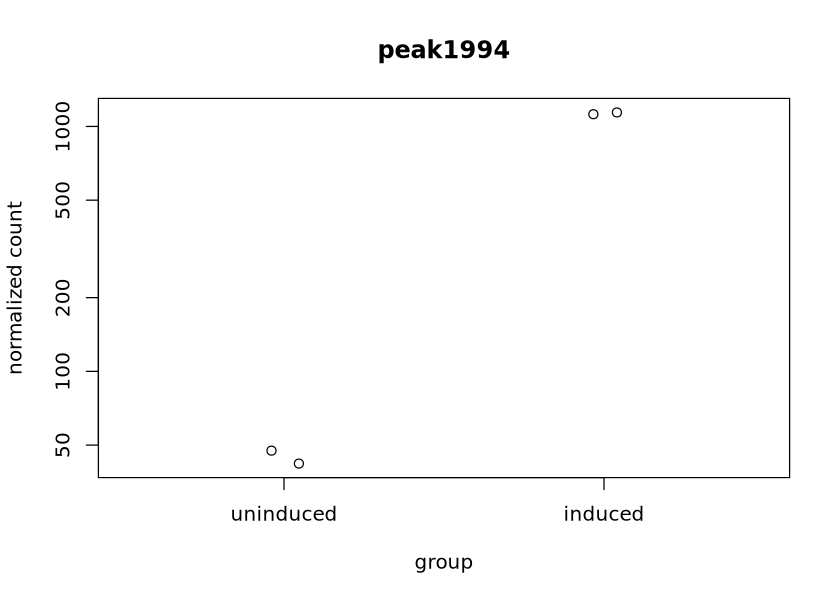

In [18]:
volcano <- as.data.frame(res_shrunk)
volcano$significant <- !is.na(volcano$padj) & volcano$padj < 0.05
ggplot(volcano, aes(log2FoldChange, -log10(pvalue), colour = significant)) +
    geom_point(size = 0.8) + scale_colour_manual(values = c("grey60", "firebrick")) +
    labs(title = "induced vs uninduced", x = "log2 fold change (shrunken)") + theme_bw()

# the region with the smallest adjusted p-value, and its normalised counts per sample
top_peak <- rownames(res)[which.min(res$padj)]
plotCounts(dds, gene = top_peak, intgroup = "dox", main = top_peak)

Let's keep the significant regions (the **differentially accessible regions**, DARs) as GRanges, with the coordinates of the consensus peaks:

In [19]:
consensus <- read.delim(file.path(nb02, "consensus_peaks.bed"), header = FALSE, col.names = c("chr", "start", "end", "name"))
# BED starts are 0-based, GRanges are 1-based: add 1
consensus_gr <- GRanges(consensus$chr, IRanges(consensus$start + 1, consensus$end), name = consensus$name)
names(consensus_gr) <- consensus$name

# significant regions (padj < 0.05; NA = removed by independent filtering), with their shrunken fold change
res_df <- as.data.frame(res_shrunk)
sig <- rownames(res_df)[!is.na(res_df$padj) & res_df$padj < 0.05]
db_deseq2 <- consensus_gr[sig]
db_deseq2$log2FoldChange <- res_df[sig, "log2FoldChange"]
db_deseq2$padj <- res_df[sig, "padj"]
db_deseq2

GRanges object with 3031 ranges and 3 metadata columns:
           seqnames            ranges strand |        name log2FoldChange
              <Rle>         <IRanges>  <Rle> | <character>      <numeric>
     peak3    chr17     233287-233786      * |       peak3       2.128476
     peak7    chr17     348545-349044      * |       peak7       1.617469
    peak10    chr17     393735-394234      * |      peak10       2.195451
    peak11    chr17     400314-400813      * |      peak11       3.474733
    peak13    chr17     410994-411493      * |      peak13      -0.799702
       ...      ...               ...    ... .         ...            ...
  peak6750    chr17 83131350-83131849      * |    peak6750       -2.98354
  peak6752    chr17 83161691-83162190      * |    peak6752        1.64337
  peak6753    chr17 83174351-83174850      * |    peak6753        1.70754
  peak6754    chr17 83188042-83188541      * |    peak6754        1.98184
  peak6755    chr17 83189628-83190127      * |    peak67

## Step 3: Comparing the methods

We now have DARs for induced vs uninduced from three approaches:

- **DiffBind** (DESeq2 inside, DiffBind's own consensus and library-size normalisation);
- **DESeq2** on our fixed-width consensus peaks (also library-size normalisation);
- **MACS3 `bdgdiff`** on pooled replicates ([part 2](part_2_consensus_peaks_macs_diff.ipynb)).

Their regions have different boundaries, so we compare them by **overlap**: a region "agrees" if it overlaps a region of another method.

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>.”
Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>.”


DiffBind   DESeq2  bdgdiff 
    3085     3031     5522

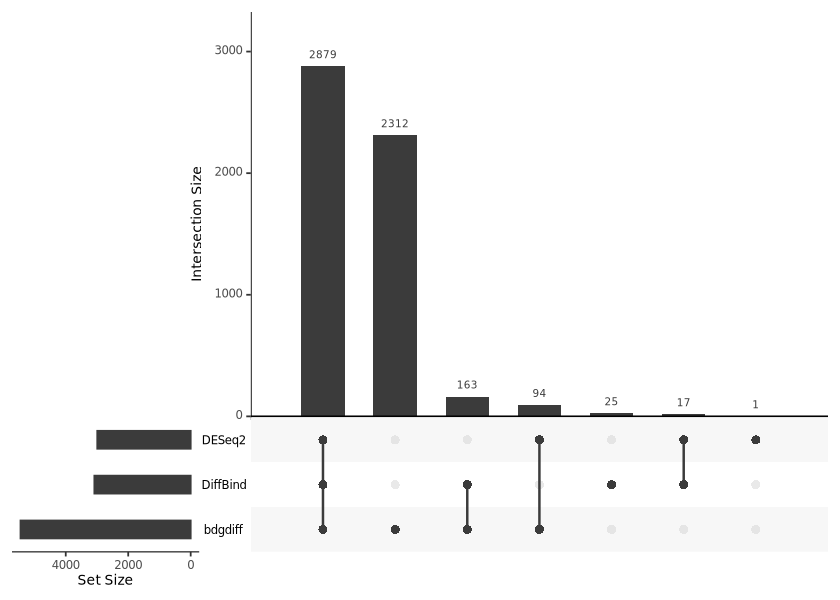

In [20]:
read_bdgdiff <- function(f) {  # bdgdiff BED (with a header line) to GRanges (1-based start)
    d <- read.delim(f, header = FALSE, skip = 1)
    GRanges(d$V1, IRanges(d$V2 + 1, d$V3))
}
db_bdgdiff <- c(read_bdgdiff(file.path(nb02, "bdgdiff", "induced_vs_uninduced_c3.0_cond1.bed")),
                read_bdgdiff(file.path(nb02, "bdgdiff", "induced_vs_uninduced_c3.0_cond2.bed")))

dar_sets <- list(DiffBind = db_diffbind, DESeq2 = db_deseq2, bdgdiff = db_bdgdiff)
sapply(dar_sets, length)

# all DAR regions together, merged; then record which method found each merged region
all_dars <- reduce(unlist(GRangesList(lapply(dar_sets, granges))))
membership <- sapply(dar_sets, function(gr) as.integer(overlapsAny(all_dars, gr)))
upset(as.data.frame(membership), order.by = "freq")

**Question**: DiffBind and our DESeq2 analysis both use DESeq2 for the test. Why don't they find exactly the same regions? And why does `bdgdiff` differ more? (Hint: list everything that happens *before* the test in each approach.)

## Step 4: Annotating DARs to genes

Which genes are near the DARs? [ChIPseeker](https://bioconductor.org/packages/ChIPseeker) assigns each region to the nearest TSS and describes its genomic context (promoter, intron, distal intergenic, ...), using the hg38 gene annotation (`TxDb.Hsapiens.UCSC.hg38.knownGene`) and gene symbols from `org.Hs.eg.db`.

'select()' returned 1:many mapping between keys and columns

'select()' returned 1:many mapping between keys and columns

'select()' returned 1:many mapping between keys and columns



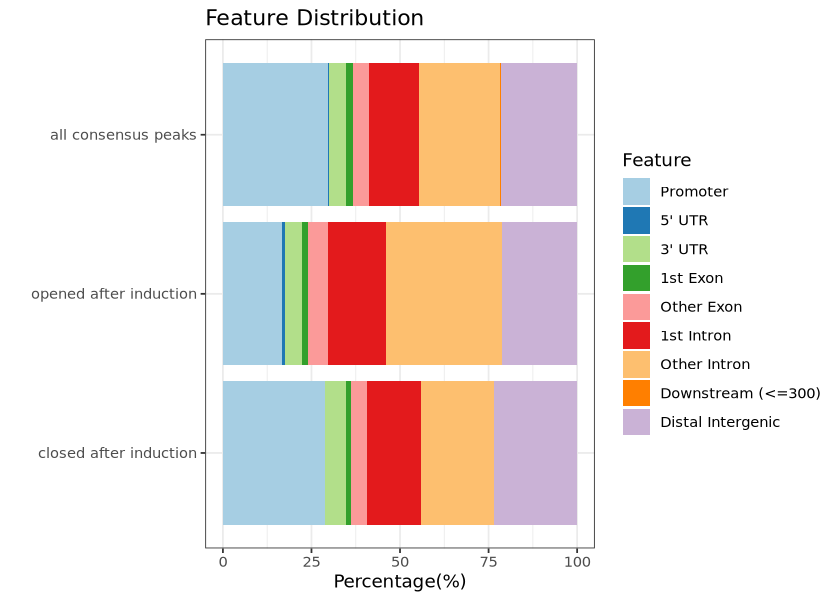

In [21]:
txdb <- TxDb.Hsapiens.UCSC.hg38.knownGene
# tssRegion: what counts as "promoter" (here ±1 kb around the TSS); annoDb adds gene symbols
annotate <- function(gr) annotatePeak(gr, TxDb = txdb, annoDb = "org.Hs.eg.db", tssRegion = c(-1000, 1000), verbose = FALSE)

anno_all <- annotate(consensus_gr)
anno_up  <- annotate(db_deseq2[db_deseq2$log2FoldChange > 0])
anno_down <- annotate(db_deseq2[db_deseq2$log2FoldChange < 0])
plotAnnoBar(list("all consensus peaks" = anno_all, "opened after induction" = anno_up, "closed after induction" = anno_down))

The opened regions are much less often at promoters than consensus peaks in general (about 17% versus 30%), and more often in introns and between genes: FOXA1 and HNF4A mostly open **distal** regions, candidate enhancers. The closed regions look like the average peak. Now the genes nearest to the strongest DARs:

In [22]:
dar_table <- rbind(as.data.frame(anno_up), as.data.frame(anno_down))
# sort by adjusted p-value and keep the most useful columns
dar_table <- dar_table[order(dar_table$padj), c("name", "seqnames", "start", "end", "log2FoldChange", "padj",
                                                "annotation", "distanceToTSS", "SYMBOL")]
# "Intron (ENST..., intron 2 of 5)" -> "Intron"
dar_table$annotation <- sub(" \\(.*", "", dar_table$annotation)
head(dar_table, 20)

,name,seqnames,start,end,log2FoldChange,padj,annotation,distanceToTSS,SYMBOL
,<chr>,<fct>,<int>,<int>,<dbl>,<dbl>,<chr>,<dbl>,<chr>
653,peak1994,chr17,31803632,31804131,4.657357,1.400286e-106,Distal Intergenic,54800,COPRS
510,peak1615,chr17,28698315,28698814,3.814113,7.322366e-98,Promoter,403,SUPT6H
1481,peak4612,chr17,59469717,59470216,4.699259,1.346776e-87,Intron,56433,LINC01476
1417,peak4445,chr17,57937989,57938488,5.654580,7.396887e-83,Intron,16769,CUEDC1
749,peak2312,chr17,35973361,35973860,6.703448,3.042262e-74,Distal Intergenic,4403,CCL16
1176,peak3758,chr17,48871629,48872128,3.130544,5.897569e-73,Distal Intergenic,-8712,LOC124900395
497,peak1575,chr17,28398151,28398650,3.515255,6.523617e-70,3' UTR,6171,SLC46A1
1894,peak5876,chr17,76161909,76162408,4.185585,7.900646e-69,Promoter,0,RNF157
1858,peak5742,chr17,75295167,75295666,3.315448,1.490247e-65,Distal Intergenic,-5657,SLC25A19


### Back to the genes of part 1

In [part 1](part_1_reads_to_peaks.ipynb) we looked at the promoters of *ASGR1*, *VTN*, *SHBG*, *SERPINF2*, *GCGR*, *CCL16* and *ACTG1* in one sample per condition. Let's look at the DESeq2 result of all consensus peaks annotated to these genes:

In [23]:
genes <- c("ASGR1", "VTN", "SHBG", "SERPINF2", "GCGR", "CCL16", "ACTG1")
# all consensus peaks near these genes, significant or not: add the DESeq2 result by region name
res_df <- as.data.frame(res_shrunk)
all_table <- as.data.frame(anno_all)
all_table$log2FoldChange <- round(res_df[all_table$name, "log2FoldChange"], 2)
all_table$padj <- signif(res_df[all_table$name, "padj"], 2)
all_table$annotation <- sub(" \\(.*", "", all_table$annotation)
near <- all_table[all_table$SYMBOL %in% genes, c("name", "SYMBOL", "annotation", "distanceToTSS", "log2FoldChange", "padj")]
near[order(near$SYMBOL, near$distanceToTSS), ]

,name,SYMBOL,annotation,distanceToTSS,log2FoldChange,padj
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
5321,peak6529,ACTG1,Promoter,0,-0.03,9.1e-01
5320,peak6528,ACTG1,Distal Intergenic,2821,0.14,7.0e-01
5319,peak6527,ACTG1,Distal Intergenic,20638,1.07,2.2e-03
5318,peak6526,ACTG1,Distal Intergenic,23879,-0.35,9.7e-02
408,peak510,ASGR1,Promoter,0,0.28,4.7e-01
409,peak511,ASGR1,Promoter,0,1.32,5.6e-04
410,peak512,ASGR1,Promoter,0,2.98,8.4e-10
407,peak509,ASGR1,Distal Intergenic,11549,0.48,2.0e-01
1871,peak2315,CCL16,Promoter,-440,3.85,1.3e-43


All six liver genes have at least one significantly opened region at their promoter or nearby. *CCL16* has a whole cluster of opened regions (promoter, 3' UTR and up to 8 kb downstream), including one of the strongest DARs on chr17 (peak2312, about 100-fold). *SERPINF2*, *ASGR1* and *GCGR* gain accessibility at the promoter, as we saw in part 1. *SHBG* and *VTN* looked unchanged in part 1, but here they have a significantly opened promoter region too: the ±1 kb window of part 1 was centred on one annotated TSS and mixed opened and unchanged signal, while the consensus peaks separate them. The control *ACTG1* does not change at its promoter (log2 fold change -0.03): with replicates and a normalisation that suits the experiment, the drop of part 1 disappears.

Remember that accessibility is not expression: a more accessible region near a gene is consistent with, but does not prove, its activation. The RNA-seq of the same cells lets us check that.

## Step 5: Do the opened regions lie near the activated genes?

The [bulk RNA-seq practical](../bulk-rna-seq/part_2_differential_expression.ipynb) found about 2,000 genes **activated** in the FOXA1-HNF4A line: log2 fold change ≥ 1, adjusted p < 0.05 and fewer than 50 normalised reads before induction (the definition of the paper). Let's repeat that analysis quickly on the RNA-seq counts of the same line (three replicates per condition, from GEO) and ask whether the opened regions are near these genes.

In [24]:
# RNA-seq of the FOXA1-HNF4A line: GEO's Salmon quantification (GSM5520301-306), summed per gene and rounded
rna <- round(as.matrix(read.delim(file.path(bulk, "rna", "foxa1hnf4a_gene_counts.tsv"), row.names = 1)))
rna_samples <- data.frame(dox = factor(ifelse(grepl("_I", colnames(rna)), "induced", "uninduced"),
                                       levels = c("uninduced", "induced")), row.names = colnames(rna))
dds_rna <- DESeqDataSetFromMatrix(rna, rna_samples, design = ~ dox)
dds_rna <- dds_rna[rowSums(counts(dds_rna) >= 10) >= 3, ]  # as in the RNA-seq practical: >= 10 reads in >= 3 samples
dds_rna <- DESeq(dds_rna, quiet = TRUE)
res_rna <- as.data.frame(lfcShrink(dds_rna, coef = "dox_induced_vs_uninduced", type = "apeglm", quiet = TRUE))
# activated: log2FC >= 1, padj < 0.05, mean normalised count < 50 before induction
res_rna$mean_uninduced <- rowMeans(counts(dds_rna, normalized = TRUE)[, rna_samples$dox == "uninduced"])
activated <- rownames(res_rna)[which(res_rna$log2FoldChange >= 1 & res_rna$padj < 0.05 & res_rna$mean_uninduced < 50)]
cat(length(activated), "activated genes genome-wide\n")

1730 activated genes genome-wide


converting counts to integer mode



We find about 1,700 activated genes (the RNA-seq practical finds about 2,000 with its own alignment and counting; the GEO quantification differs slightly). Now, for every protein-coding gene on chr17 that is expressed in at least one condition (it passed the filter of the RNA analysis), we ask: is there an **opened** region within a window around its TSS? If FOXA1 and HNF4A switch genes on by opening nearby regulatory regions, activated genes should have such a region more often than other genes. The paper used a window of 50 kb; we compare a few window sizes.

In [25]:
# TSS of the expressed protein-coding genes on chr17 (gene symbols, as in the RNA counts)
tss <- read.delim(file.path(bulk, "genome", "hg38", "hg38_tss_protein_coding.bed"), header = FALSE,
                  col.names = c("chr", "start", "end", "gene", "score", "strand"))
tss <- tss[tss$chr == "chr17" & tss$gene %in% rownames(res_rna), ]
is_activated <- tss$gene %in% activated
cat(nrow(tss), "expressed genes on chr17, of which", sum(is_activated), "activated\n")

opened <- db_deseq2[db_deseq2$log2FoldChange > 0]
window_test <- do.call(rbind, lapply(c(5, 10, 20, 50), function(kb) {
    # the TSS extended by kb on both sides; countOverlaps: number of opened regions in each window
    win <- GRanges(tss$chr, IRanges(pmax(1, tss$start + 1 - kb * 1000), tss$end + kb * 1000))
    n_opened <- countOverlaps(win, opened)
    data.frame(window_kb = kb,
               activated_with_opened = round(mean(n_opened[is_activated] > 0), 2),
               other_with_opened = round(mean(n_opened[!is_activated] > 0), 2),
               mean_opened_activated = round(mean(n_opened[is_activated]), 1),
               mean_opened_other = round(mean(n_opened[!is_activated]), 1))
}))
window_test

860 expressed genes on chr17, of which 59 activated


window_kb,activated_with_opened,other_with_opened,mean_opened_activated,mean_opened_other
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
5,0.58,0.23,0.8,0.3
10,0.80,0.45,1.4,0.6
20,0.93,0.69,2.5,1.3
50,0.98,0.92,4.9,3.5


Activated genes clearly have more opened regions nearby: within 10 kb of the TSS, 80% of the activated genes have at least one opened region, against 45% of the other expressed genes, and on average more than twice as many. The window size matters: within 50 kb almost every gene on chr17 has an opened region (chr17 is gene-dense, and FOXA1 and HNF4A open more than 2,000 regions on it), so a large window no longer separates activated from other genes. The paper did not count all opened regions, but only regions **bound** by FOXA1 and HNF4A in ChIP-seq: of 53 co-bound sites within 50 kb of activated liver genes, 43 were inaccessible before induction and opened.

Conversely, about 20% of the activated genes have no opened region within 10 kb. Some may be regulated by enhancers further away, others by regions that were already accessible before induction, where binding of FOXA1 or HNF4A (which ATAC-seq does not measure) is enough. And many opened regions are not near an activated gene: opening chromatin is not sufficient to switch a gene on.

## Step 6: Which motifs are in the opened regions?

If FOXA1 and HNF4A open these regions themselves, the opened regions should contain their binding motifs. **Known-motif enrichment** compares how often each motif of a database occurs in a set of target regions and in a set of background regions. We use [HOMER](http://homer.ucsd.edu/homer/motif/) `findMotifsGenome.pl`, with:

- the opened regions as targets, and **all consensus peaks** as background: the background has the same GC content and the same "accessible in K562" character, so we find what is special about the opened regions, not just what is typical for accessible DNA;
- `-size 200`: the central 200 bp of each region (our 500 bp regions are centred on the summit, where the factors bind);
- `-nomotif`: only known motifs (no de novo search, which takes much longer).

HOMER is a command-line tool, so we call it from R with `system2`. This takes a few minutes.

In [26]:
write_bed <- function(gr, file) {  # GRanges (1-based) to BED (0-based start), with the region name in column 4
    write.table(data.frame(seqnames(gr), start(gr) - 1, end(gr), names(gr), ".", "+"), file,
                sep = "\t", quote = FALSE, row.names = FALSE, col.names = FALSE)
}
write_bed(consensus_gr, "consensus_background.bed")
dir.create("preparsed", showWarnings = FALSE)

known_motifs <- function(gr, name) {  # HOMER known-motif enrichment of gr against all consensus peaks
    write_bed(gr, paste0(name, ".bed"))
    # findMotifsGenome.pl <targets> <genome fasta> <output folder>; -bg: background regions; -p: threads;
    # -preparsedDir: where HOMER stores the background sequences it extracts from the genome
    system2("findMotifsGenome.pl", c(paste0(name, ".bed"), file.path(bulk, "genome", "hg38", "chr17.fa"),
                                     paste0("homer_", name), "-size 200", "-nomotif",
                                     "-bg consensus_background.bed", "-p 4", "-preparsedDir preparsed"),
            stdout = paste0("homer_", name, ".log"), stderr = paste0("homer_", name, ".log"))
    known <- read.delim(file.path(paste0("homer_", name), "knownResults.txt"), check.names = FALSE)
    # column 1: motif name (motif/origin/database); HOMER's p-value is a natural log, we convert it to log10;
    # the % columns: fraction of target and background regions with the motif
    data.frame(motif = sub("/.*", "", known[[1]]), log10_p = round(known[["Log P-value"]] / log(10)),
               targets = known[["% of Target Sequences with Motif"]],
               background = known[["% of Background Sequences with Motif"]])
}
motifs_opened <- known_motifs(opened, "opened")
head(motifs_opened, 15)

,motif,log10_p,targets,background
,<chr>,<dbl>,<chr>,<chr>
1,"HNF4a(NR),DR1",-334,29.65%,4.23%
2,"PPARa(NR),DR1",-179,33.92%,10.65%
3,RARa(NR),-166,61.49%,32.26%
4,FOXA1(Forkhead),-165,37.61%,13.68%
5,Foxa2(Forkhead),-158,28.04%,8.17%
6,FOXM1(Forkhead),-144,33.21%,11.94%
7,FOXA1(Forkhead),-143,33.63%,12.30%
8,"Fox:Ebox(Forkhead,bHLH)",-114,28.28%,10.45%
9,"PPARE(NR),DR1",-113,26.10%,9.15%


The two most enriched motif families are exactly the two factors we switched on. The HNF4A motif (a DR1 element: two half-sites with one base in between) is found in about 30% of the opened regions but only 4% of the background, and the forkhead motifs of FOXA1 and FOXA2 in about 38% versus 14%. The other nuclear receptors in the list (PPARα, RXR, RARα, TR4) bind very similar DR1 elements, and FOXM1 and PHA-4 are other forkhead factors: motif databases are redundant, so read the list by motif family rather than by single name. The motifs of the opened regions confirm that FOXA1 and HNF4A open these regions themselves.

What about the regions that **close** after induction?

In [27]:
motifs_closed <- known_motifs(db_deseq2[db_deseq2$log2FoldChange < 0], "closed")
head(motifs_closed, 10)

,motif,log10_p,targets,background
,<chr>,<dbl>,<chr>,<chr>
1,GATA3(Zf),-48,43.15%,21.51%
2,Gata4(Zf),-46,36.09%,16.54%
3,Gata6(Zf),-43,34.02%,15.48%
4,TRPS1(Zf),-42,46.63%,25.66%
5,Gata1(Zf),-39,27.72%,11.69%
6,Gata2(Zf),-37,29.13%,13.03%
7,At5g05790(MYBrelated),-32,26.96%,12.48%
8,At3g11280(MYBrelated),-31,26.09%,11.91%
9,At1g49010(MYBrelated),-27,35.76%,20.18%


The closed regions tell another story: they are enriched for **GATA** motifs (about 30-45% of the regions against 12-25% of the background). The GATA family is one family of zinc-finger motifs, so GATA3, GATA4 and GATA6 in the list cannot be told apart from GATA1, the master regulator of the erythroid program of K562 cells. The enrichment is weaker than for the opened regions, but it shows that at least part of the closing is biology rather than normalisation: when FOXA1 and HNF4A move in, some regions of the cell's own GATA-driven program lose accessibility. Whether this is direct competition or a secondary effect of the new gene expression program cannot be decided from these data.

## Step 7: Saving the results

We write the DARs as BED files (for IGV, or for other downstream analyses) and the full result table.

In [28]:
# write_bed() was defined in Step 6
write_bed(opened, "DARs_opened.bed")
write_bed(db_deseq2[db_deseq2$log2FoldChange < 0], "DARs_closed.bed")
write.table(dar_table, "DARs_induced_vs_uninduced_annotated.tsv", sep = "\t", quote = FALSE, row.names = FALSE)
list.files()

[1] "closed.bed"                             
 [2] "consensus_background.bed"               
 [3] "DARs_closed.bed"                        
 [4] "DARs_induced_vs_uninduced_annotated.tsv"
 [5] "DARs_opened.bed"                        
 [6] "homer_closed"                           
 [7] "homer_closed.log"                       
 [8] "homer_opened"                           
 [9] "homer_opened.log"                       
[10] "opened.bed"                             
[11] "preparsed"

## Comparison with the paper

Hansen et al. made ATAC-seq libraries of the FOXA1, HNF4A and FOXA1-HNF4A lines (Omni-ATAC, two replicates per condition) and combined them with ChIP-seq of FOXA1 and HNF4A. Their ATAC-seq analysis focused on the regions **bound** by the two factors: they did not report genome-wide numbers of opened and closed regions.

| | this practical | paper |
|---|---|---|
| data | FOXA1-HNF4A line, chr17 only | all three lines, genome-wide, plus ChIP-seq |
| alignment | bowtie2 `--very-sensitive -X 2000` | bowtie2 `--local -X 2000` |
| peaks | MACS3, paired-end mode, q < 0.01 | MACS2, p < 0.01, reproducible peaks with IDR |
| differential test | DiffBind + DESeq2; DESeq2 on our own consensus | DiffBind |
| normalisation | library size (RLE gives extra "closed" regions) | not stated |
| opened regions | about 2,100 on chr17, mostly distal | most FOXA1 and HNF4A binding sites were inaccessible before induction and opened |
| motifs in opened regions | HNF4A (DR1) and forkhead (FOXA) motifs, by far the strongest (HOMER, known motifs) | only the factor's own motif at the sites it opened (STREME, de novo); no motifs of K562 factors |
| link with expression | 80% of the activated genes on chr17 have an opened region within 10 kb (45% of the other genes) | 43 of 53 co-bound sites within 50 kb of activated liver genes were inaccessible before induction |

Our results agree with the paper's main conclusions: FOXA1 and HNF4A open many closed regions, the opened regions carry their motifs, and they lie near the activated genes. Because both factors are expressed together in this line, we cannot say which of the two opens a given region; the paper answers that with the single-factor lines and ChIP-seq, and concludes that HNF4A, not considered a pioneer factor, also opens closed chromatin on its own. We also find something the comparison above does not cover: regions that close after induction, enriched for GATA motifs.

## Conclusion

1. **How good are the libraries?** Good: almost all reads align, the TSS enrichment and FRiP are above the ENCODE thresholds and similar for all four samples, and the replicates agree closely. Mitochondrial reads (18-30%) and duplicates cost sequencing depth but not quality. The induced samples have more peaks and a higher FRiP, not because they are better libraries, but because more of their chromatin is open.
2. **Which regions open or close?** On chr17 about 2,100 regions open and 900 close after expression of FOXA1 and HNF4A (DESeq2 and DiffBind agree, with library-size normalisation). The opened regions are mostly distal: candidate enhancers. RLE normalisation, which assumes that most regions do not change, would add hundreds of falsely "closed" regions in this experiment.
3. **Motifs and genes?** The opened regions are strongly enriched for the HNF4A and FOXA motifs, so the two factors open them directly, and they lie near the genes that the RNA-seq practical found activated: *CCL16*, *SERPINF2*, *ASGR1*, *GCGR*, *SHBG* and *VTN* all gain accessibility, the control *ACTG1* does not. The closed regions are enriched for GATA motifs, the motifs of the K562 cells' own erythroid program.

What to remember beyond this dataset:

- **Replicates** make differential accessibility testable: DiffBind and DESeq2 estimate the variation between replicates and control the false discovery rate; MACS3 `bdgdiff` cannot.
- **Normalisation is a biological assumption**: library-size normalisation assumes the same background in every sample, RLE that most regions do not change. When a treatment opens chromatin globally, as pioneer factors do, the second assumption fails. Check the MA plot and think about the biology.
- **Combine assays**: accessibility tells you *where* the chromatin changes, motifs suggest *which factors* are responsible, and RNA-seq of the same cells tells you *which genes* respond.

In the next practical we move to [**single-cell ATAC-seq**](../single-cell-atac-seq/index.md), where accessibility is measured in thousands of individual cells, and the same liver transcription factors (FOXA, HNF4A) shape the regulatory landscape of hepatocytes in their natural context.

## Exercises

1. Repeat the DESeq2 analysis of Step 2 with DESeq2's own RLE size factors (`estimateSizeFactors(dds)` instead of the library-size factors). How many regions open and close? Make an MA plot (`plotMA`): where is the cloud of unchanged regions now?
2. Repeat the motif enrichment for the opened regions with a different background: instead of all consensus peaks, let HOMER choose random genomic regions with the same GC content (leave out `-bg`). Which motifs appear now that did not before, and why?
3. Which activated genes on chr17 have no opened region within 10 kb (`tss$gene[is_activated]` and `countOverlaps`)? Look at one of them in IGV with the bigWig files of part 1: is there an opened region further away, or an accessible region that does not change?
4. Annotate the DARs found by DiffBind (`db_diffbind`) with ChIPseeker. Are they in the same genomic contexts as the DESeq2 DARs?